In [94]:
import os
import numpy as np
import rasterio
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay
import joblib
import warnings
warnings.filterwarnings('ignore')

In [95]:
import rasterio

# Open multi-band image
with rasterio.open(r'C:\Users\ALI\Desktop\sat_Project\S2_ML_Dataset_V2\CairoDowntown_12band.tif') as src:
    print(f"Shape: {src.shape}")  # (rows, cols)
    print(f"Number of bands: {src.count}")
    print(f"Dimensions: {src.width} x {src.height}")
    
    # Read all bands into a numpy array
    img_array = src.read()  # Shape: (bands, rows, cols)
    print(f"Array shape: {img_array.shape}")
    
    # Access specific band
    band1 = src.read(1)  # First band
    print(f"Band 1 shape: {band1.shape}")

Shape: (602, 691)
Number of bands: 12
Dimensions: 691 x 602
Array shape: (12, 602, 691)
Band 1 shape: (602, 691)


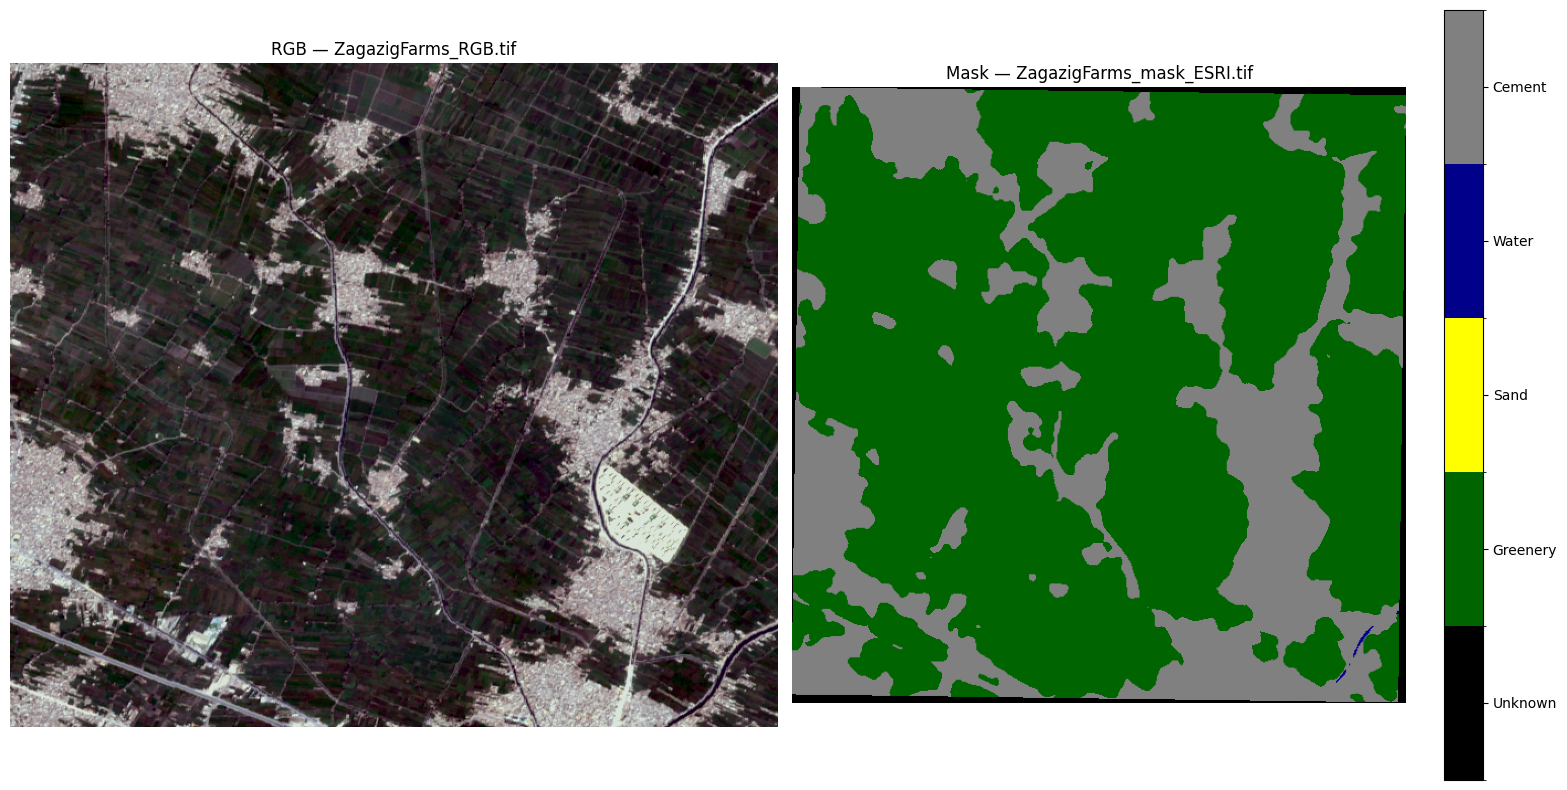

In [ ]:
def show_rgb_and_mask(rgb_path, mask_path):
    with rasterio.open(rgb_path) as src:
        r = src.read(1).astype(float)
        g = src.read(2).astype(float)
        b = src.read(3).astype(float)

    def stretch(band, low=1, high=99):
        p_low, p_high = np.percentile(band[band > 0], [low, high])
        band = np.clip(band, p_low, p_high)
        return (band - p_low) / (p_high - p_low)

    rgb = np.stack([stretch(r), stretch(g), stretch(b)], axis=-1)
    rgb = np.power(rgb, 0.75)
    rgb[:, :, 0] *= 0.85
    rgb[:, :, 1] *= 0.90
    rgb[:, :, 2] *= 0.85
    rgb = np.clip(rgb, 0, 1)

    with rasterio.open(mask_path) as src:
        mask = src.read(1)

    cmap = mcolors.ListedColormap(['black', 'darkgreen', 'yellow', 'darkblue', 'gray'])
    norm = mcolors.BoundaryNorm([0, 1, 2, 3, 4, 5], cmap.N)

    fig, axes = plt.subplots(1, 2, figsize=(16, 8))

    axes[0].imshow(rgb)
    axes[0].set_title('RGB — ' + os.path.basename(rgb_path))
    axes[0].axis('off')

    im = axes[1].imshow(mask, cmap=cmap, norm=norm)
    cbar = plt.colorbar(im, ax=axes[1], ticks=[0.5, 1.5, 2.5, 3.5, 4.5])
    cbar.ax.set_yticklabels(['Unknown', 'Greenery', 'Sand', 'Water', 'Cement'])
    axes[1].set_title('Mask — ' + os.path.basename(mask_path))
    axes[1].axis('off')

    plt.tight_layout()
    plt.show()


BASE = r'C:\Users\ALI\Desktop\sat_Project\S2_ML_Dataset_V2\ZagazigFarms'
show_rgb_and_mask(
    rgb_path  = BASE + r'_RGB.tif',
    mask_path = BASE + r'_mask_ESRI.tif'
)

In [161]:
BASE = r'C:\Users\ALI\Desktop\sat_Project\S2_ML_Dataset_V2'
MODEL_DIR = r'C:\Users\ALI\Desktop\sat_Project\models'
os.makedirs(MODEL_DIR, exist_ok=True)

# Class names matching project spec
CLASS_NAMES  = ['Greenery', 'Sand', 'Water', 'Cement']
CLASS_LABELS = [1, 2, 3, 4]
TRAIN_LOCS = [
    'BaharyaOasis', 'EasternDesert', 'FarafraOasis', 'KhargaOasis',
    'LibyanBorder', 'WadiElGemal', 'WhiteDesert',

    'AssiutFarms', 'BeheiraNileDelta', 'DakhlaOasis', 'DamietaFarms',
    'HawaraFayoum', 'MiniaFarms', 'NileDelta', 'SohagFarms',
    'WadiNatrun', 'ZagazigFarms',

    'AlexandriaPort', 'CairoDowntown', 'CairoUniv', 'FayoumFarms',
    'GizaPlateau', 'HelwanIndustrial', 'MansouraCity', 'NaserCity',

    'AbuSimbelDesert', 'BardawilLake', 'GreatBitterLake', 'GulfSuez',
    'ManzalaLake', 'NasserLake', 'RedSeaHurghada', 'SaddElAly', 'SuezCanal',
]

VAL_LOCS = [
    'IconicTower', 'QattaraDepression',

    'KarnakLuxor', 'SiwaOasis',

    'PortSaidCity', 'ZagazigCity',

    'GulfAqaba', 'MariutLake',
]

TEST_LOCS = [
    'SinaiDesert', 'WadiRum',

    'QenaFarms', 'TantaCity',

    'NileCairo', 'SuezCity',

    'QarunLake', 'TimsahLake',
]

In [162]:
def compute_composite_bands(bands):
    """
    Compute composite bands as taught in the Remote Sensing lectures.
    Band order: B1,B2,B3,B4,B5,B6,B7,B8,B8A,B9,B11,B12
    Index:       0   1   2   3   4   5   6   7   8    9  10   11
    """
    B2   = bands[1].astype(float)   # Blue
    B3   = bands[2].astype(float)   # Green
    B4   = bands[3].astype(float)   # Red
    B8   = bands[7].astype(float)   # NIR
    B8A  = bands[8].astype(float)   # NIR narrow
    B11  = bands[10].astype(float)  # SWIR-1
    B12  = bands[11].astype(float)  # SWIR-2
    eps  = 1e-10

    # --- Composite bands from lectures ---
    NDVI     = (B8  - B4)  / (B8  + B4  + eps)  # Vegetation Index (NDVI)
    MOISTURE = (B8A - B11) / (B8A + B11 + eps)  # Moisture Index
    NDWI     = (B3  - B8)  / (B3  + B8  + eps)  # NDWI — Water detection
    NDBI     = (B11 - B8)  / (B11 + B8  + eps)  # NDBI — Built-up index
    BSI      = ((B11 + B4) - (B8 + B2)) / ((B11 + B4) + (B8 + B2) + eps) # bare boil index: separates sand from cement
    return np.stack([NDVI, MOISTURE, NDWI, NDBI, BSI], axis=0) 


def load_features_and_labels(name):
    img_path  = os.path.join(BASE, f'{name}_12band.tif')
    mask_path = os.path.join(BASE, f'{name}_mask_ESRI.tif')

    with rasterio.open(img_path) as src:
        bands = src.read().astype(np.float32)   

    with rasterio.open(mask_path) as src:
        mask = src.read(1)                      
    
    H = min(bands.shape[1], mask.shape[0])
    W = min(bands.shape[2], mask.shape[1])
    bands = bands[:, :H, :W]
    mask  = mask[:H, :W]
    
    bands = np.clip(bands / 10000.0, 0, 1)
    composites = compute_composite_bands(bands)
    features = np.concatenate([bands, composites], axis=0) 
    return features, mask


def extract_training_pixels(locations):
    X_all, y_all = [], []
    for name in locations:
        try:
            features, mask = load_features_and_labels(name)
            X = features.reshape(17, -1).T  
            y = mask.flatten()                
            valid = y > 0                     
            X_all.append(X[valid])
            y_all.append(y[valid])
        except Exception as e:
            print(f'{name}: {e}')
    return np.vstack(X_all), np.concatenate(y_all)

In [163]:
print('supervised classification — data loading')
print('\nLoading training pixels')
X_train, y_train = extract_training_pixels(TRAIN_LOCS)

print('\nLoading validation pixels')
X_val, y_val = extract_training_pixels(VAL_LOCS)

print('\nLoading test pixels')
X_test, y_test = extract_training_pixels(TEST_LOCS)

print(f'\nDataset Summary:')
print(f'Train: {X_train.shape[0]:>10,} pixels | {X_train.shape[1]} features')
print(f'Val: {X_val.shape[0]:>10,} pixels')
print(f'Test: {X_test.shape[0]:>10,} pixels')

print('\nClass distribution in training set:')
for cls, name in zip(CLASS_LABELS, CLASS_NAMES):
    count = (y_train == cls).sum()
    pct= 100 * count / len(y_train)
    print(f'{name:<20}: {count:>8,} pixels ({pct:.1f}%)')

supervised classification — data loading

Loading training pixels

Loading validation pixels

Loading test pixels

Dataset Summary:
Train: 12,155,132 pixels | 17 features
Val:  2,861,415 pixels
Test:  2,862,018 pixels

Class distribution in training set:
Greenery            : 3,384,277 pixels (27.8%)
Sand                : 2,753,285 pixels (22.7%)
Water               : 2,926,076 pixels (24.1%)
Cement              : 3,091,494 pixels (25.4%)


In [166]:
from tqdm import tqdm

def balanced_subsample(X, y, n_per_class=600_000):
    X_out, y_out = [], []
    for cls, name in zip(CLASS_LABELS, CLASS_NAMES):
        idx    = np.where(y == cls)[0]
        n_take = min(len(idx), n_per_class)
        chosen = np.random.RandomState(42).choice(idx, n_take, replace=False)
        X_out.append(X[chosen])
        y_out.append(y[chosen])
        print(f'  {name:<20}: {n_take:,} pixels')
    return np.vstack(X_out), np.concatenate(y_out)

print('Balanced sampling...')
X_tr, y_tr = balanced_subsample(X_train, y_train, n_per_class=600_000)
print(f'Total: {len(X_tr):,} pixels (perfectly balanced)')

scaler   = StandardScaler()
X_tr_s   = scaler.fit_transform(X_tr)
X_val_s  = scaler.transform(X_val)
X_test_s = scaler.transform(X_test)

print('\nTraining Random Forest...')
N_ESTIMATORS = 200

rf = RandomForestClassifier(
    n_estimators     = 1,
    warm_start       = True,
    max_depth        = 20,
    min_samples_leaf = 5,
    class_weight     = 'balanced',
    n_jobs           = 4,
    random_state     = 42,
    verbose          = 0,
    max_samples      = 0.8
)

with tqdm(total=N_ESTIMATORS, desc='Training trees', unit='tree') as pbar:
    for i in range(1, N_ESTIMATORS + 1):
        rf.n_estimators = i
        rf.fit(X_tr_s, y_tr)
        pbar.update(1)

joblib.dump(rf,     os.path.join(MODEL_DIR, 'rf_model.pkl'))
joblib.dump(scaler, os.path.join(MODEL_DIR, 'scaler.pkl'))
print('Model saved!')

Balanced sampling...
  Greenery            : 600,000 pixels
  Sand                : 600,000 pixels
  Water               : 600,000 pixels
  Cement              : 600,000 pixels
Total: 2,400,000 pixels (perfectly balanced)

Training Random Forest...


Training trees: 100%|██████████| 200/200 [52:03<00:00, 15.62s/tree]


Model saved!



ACCURACY ASSESSMENT — Validation

Error Matrix (Confusion Matrix):


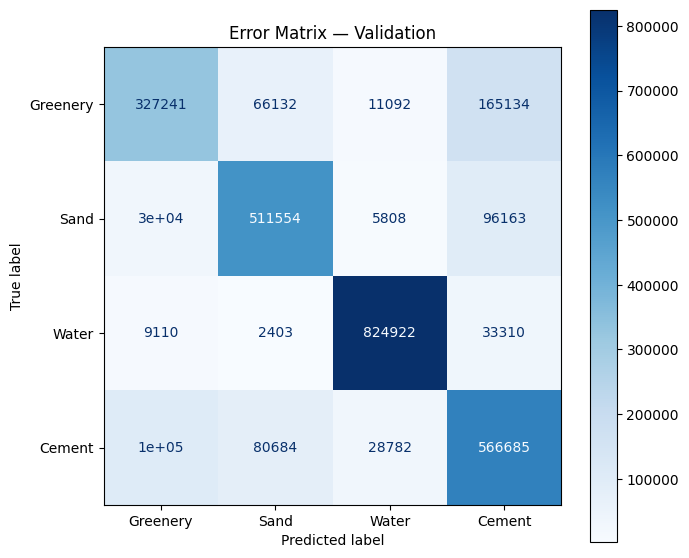


Errors of Omission (False Negatives / True class total):
  Greenery            : 0.4255
  Sand                : 0.2054
  Water               : 0.0515
  Cement              : 0.2718

Errors of Commission (False Positives / Predicted class total):
  Greenery            : 0.3019
  Sand                : 0.2258
  Water               : 0.0525
  Cement              : 0.3421

mIoU Score: 0.6336
Per-class IoU:
  Greenery            : 0.4602
  Sand                : 0.6451
  Water               : 0.9011
  Cement              : 0.5282

Classification Report:
              precision    recall  f1-score   support

    Greenery       0.70      0.57      0.63    569599
        Sand       0.77      0.79      0.78    643818
       Water       0.95      0.95      0.95    869745
      Cement       0.66      0.73      0.69    778253

    accuracy                           0.78   2861415
   macro avg       0.77      0.76      0.76   2861415
weighted avg       0.78      0.78      0.78   2861415


ACCURACY A

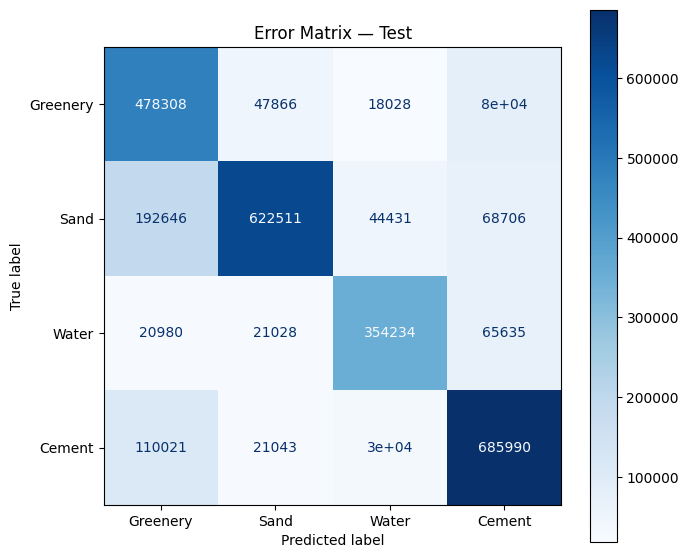


Errors of Omission (False Negatives / True class total):
  Greenery            : 0.2341
  Sand                : 0.3294
  Water               : 0.2331
  Cement              : 0.1904

Errors of Commission (False Positives / Predicted class total):
  Greenery            : 0.4036
  Sand                : 0.1262
  Water               : 0.2075
  Cement              : 0.2383

mIoU Score: 0.6001
Per-class IoU:
  Greenery            : 0.5045
  Sand                : 0.6114
  Water               : 0.6387
  Cement              : 0.6460

Classification Report:
              precision    recall  f1-score   support

    Greenery       0.60      0.77      0.67    624506
        Sand       0.87      0.67      0.76    928294
       Water       0.79      0.77      0.78    461877
      Cement       0.76      0.81      0.78    847341

    accuracy                           0.75   2862018
   macro avg       0.76      0.75      0.75   2862018
weighted avg       0.77      0.75      0.75   2862018



In [167]:
def compute_miou(y_true, y_pred):
    """IoU per class as required by project grading formula."""
    iou_dict = {}
    for c in CLASS_LABELS:
        TP = ((y_pred == c) & (y_true == c)).sum()
        FP = ((y_pred == c) & (y_true != c)).sum()
        FN = ((y_pred != c) & (y_true == c)).sum()
        iou_dict[c] = TP / (TP + FP + FN + 1e-10)
    return iou_dict, np.mean(list(iou_dict.values()))


def full_evaluation(split_name, X, y):
    """
    Step 6 from lecture:
    'Assessing the accuracy of the final product using a labelled testing data set'
    Including: Error Matrix (confusion matrix), omission/commission errors
    """
    pred = rf.predict(X)

    print(f'\n{"=" * 50}')
    print(f'ACCURACY ASSESSMENT — {split_name}')
    print(f'{"=" * 50}')

    # --- Confusion Matrix (Error Matrix) as taught in lecture ---
    cm = confusion_matrix(y, pred, labels=CLASS_LABELS)
    print('\nError Matrix (Confusion Matrix):')
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=CLASS_NAMES)
    fig, ax = plt.subplots(figsize=(7, 6))
    disp.plot(ax=ax, colorbar=True, cmap='Blues')
    ax.set_title(f'Error Matrix — {split_name}')
    plt.tight_layout()
    plt.savefig(os.path.join(MODEL_DIR, f'confusion_matrix_{split_name}.png'), dpi=150)
    plt.show()

    # --- Omission and Commission Errors (lecture terminology) ---
    print('\nErrors of Omission (False Negatives / True class total):')
    for i, name in enumerate(CLASS_NAMES):
        omission = 1 - (cm[i, i] / cm[i].sum() + 1e-10)
        print(f'  {name:<20}: {omission:.4f}')

    print('\nErrors of Commission (False Positives / Predicted class total):')
    for i, name in enumerate(CLASS_NAMES):
        commission = 1 - (cm[i, i] / cm[:, i].sum() + 1e-10)
        print(f'  {name:<20}: {commission:.4f}')

    # --- mIoU (project grading metric) ---
    iou_dict, miou = compute_miou(y, pred)
    print(f'\nmIoU Score: {miou:.4f}')
    print('Per-class IoU:')
    for cls, name in zip(CLASS_LABELS, CLASS_NAMES):
        print(f'  {name:<20}: {iou_dict[cls]:.4f}')

    # --- Classification report ---
    print('\nClassification Report:')
    print(classification_report(y, pred, target_names=CLASS_NAMES, labels=CLASS_LABELS))

    return miou, iou_dict


val_miou,  val_iou  = full_evaluation('Validation', X_val_s,  y_val)
test_miou, test_iou = full_evaluation('Test',       X_test_s, y_test)

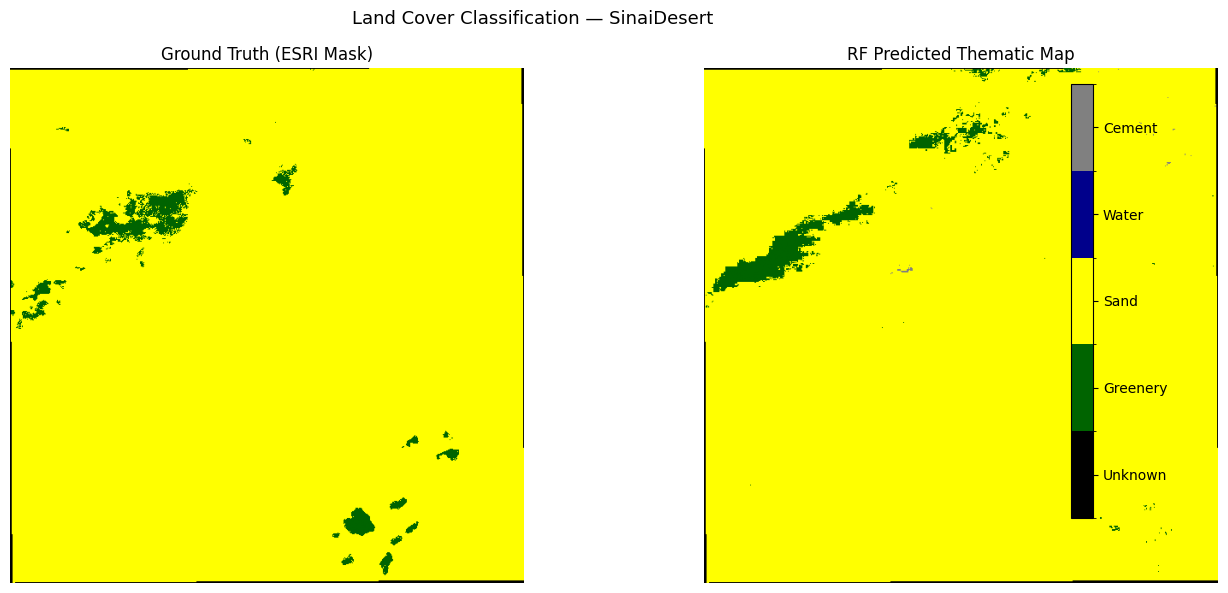

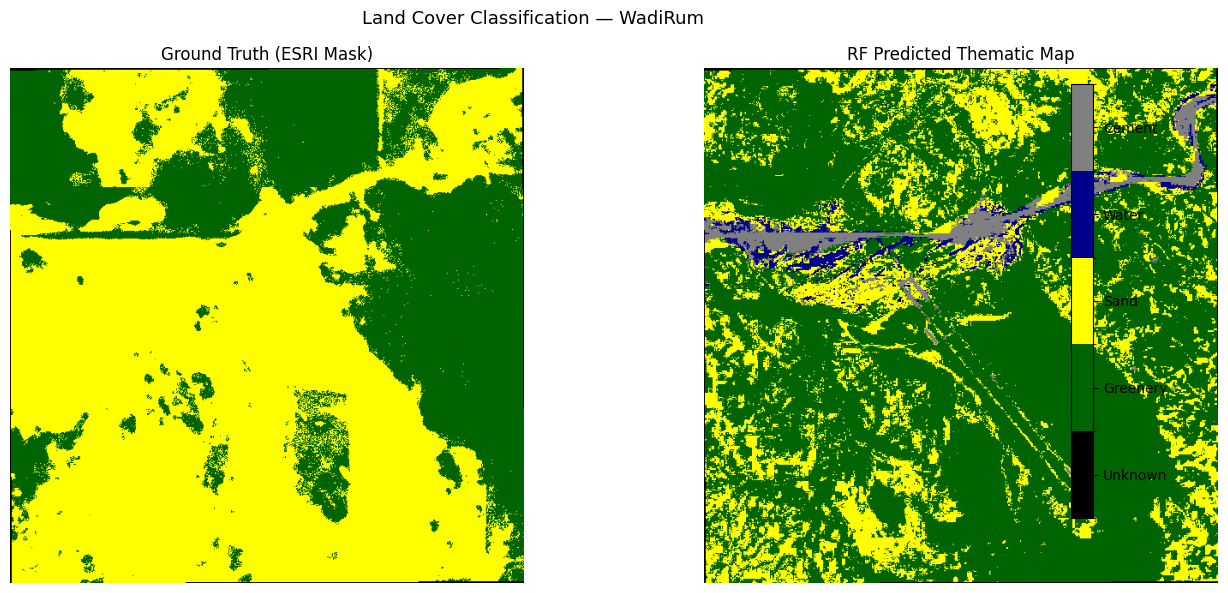

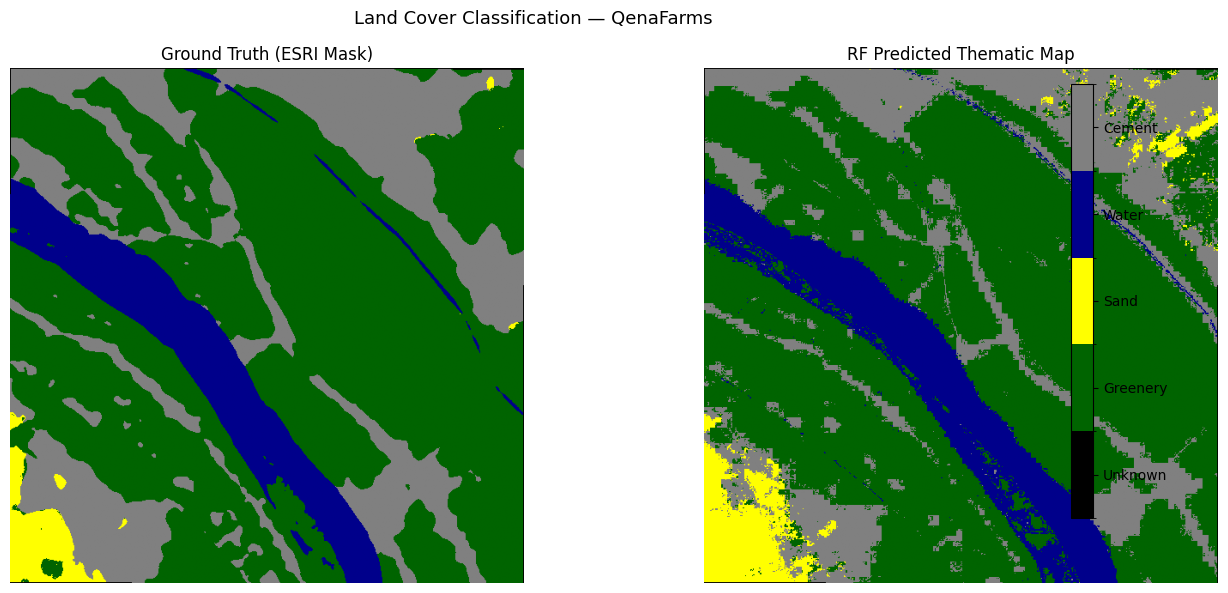

In [168]:
def predict_and_visualize(name):
    """
    Step 4-5 from lecture:
    'Using the trained classifier to label every pixel'
    'Producing thematic (class) maps'
    """
    features, mask = load_features_and_labels(name)
    H, W = mask.shape

    X       = features.reshape(17, -1).T
    X_sc    = scaler.transform(X)
    pred    = rf.predict(X_sc).reshape(H, W)
    pred[mask == 0] = 0   # restore Unknown boundary pixels

    cmap = mcolors.ListedColormap(['black','darkgreen','yellow','darkblue','gray'])
    norm = mcolors.BoundaryNorm([0,1,2,3,4,5], cmap.N)

    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    axes[0].imshow(mask,  cmap=cmap, norm=norm)
    axes[0].set_title('Ground Truth (ESRI Mask)')
    axes[0].axis('off')

    im = axes[1].imshow(pred, cmap=cmap, norm=norm)
    axes[1].set_title('RF Predicted Thematic Map')
    axes[1].axis('off')

    cbar = plt.colorbar(im, ax=axes, ticks=[0.5,1.5,2.5,3.5,4.5],
                        fraction=0.02, pad=0.04)
    cbar.ax.set_yticklabels(['Unknown','Greenery','Sand','Water','Cement'])
    plt.suptitle(f'Land Cover Classification — {name}', fontsize=13)
    plt.tight_layout()
    plt.savefig(os.path.join(MODEL_DIR, f'{name}_thematic_map.png'), dpi=150)
    plt.show()

for loc in TEST_LOCS[:3]:
    predict_and_visualize(loc)